In [1]:
%pip install torch torchvision torchaudio --index-url https://pytorch.org

Looking in indexes: https://pytorch.org, https://pypi.ngc.nvidia.com
ERROR: Could not find a version that satisfies the requirement torchaudio (from versions: none)
ERROR: No matching distribution found for torchaudio
Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install -q torch-geometric rdkit pandas scikit-learn matplotlib


[notice] A new release of pip is available: 23.3.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, BatchNorm, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Configure device and seeds
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and filter dataset
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
df_clean = df_all[['Smiles', 'pIC50']].copy()
display(df_clean.head())

,Smiles,pIC50
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,O=C(NCCc1ccc(Cl)cc1)c1ccc2nc3c(c(Cl)c2c1)CCCC3,3.698970
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272


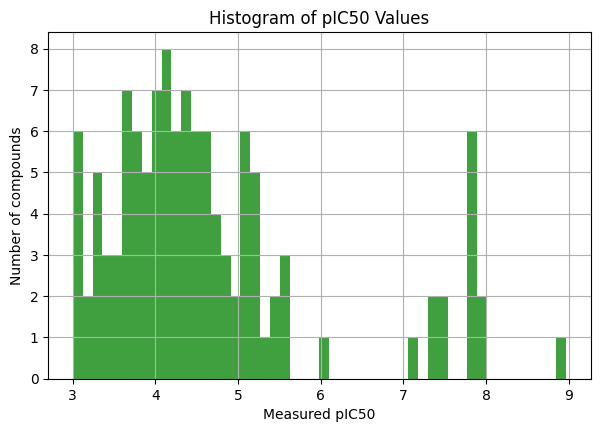

In [2]:
# 2. Plotting Target Distribution Histogram
pIC50_vals = df_clean['pIC50'].values
pIC50_vals = [val for val in pIC50_vals if val is not None and val != '']

plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75)
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True)
plt.show()

In [9]:
def one_hot(val, allowed):
    if val not in allowed:
        return [0] * len(allowed)
    return [1 if val == a else 0 for a in allowed]

def featurize_atom(atom):
    feats = []
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def convert_smiles_to_graph_data(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [featurize_atom(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[target]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

In [10]:
# 3. Target Standardization & Advanced Atom Featurization
y_raw_arr = df_clean['pIC50'].values.astype(np.float32)
y_mean_val = y_raw_arr.mean()
y_std_val = y_raw_arr.std()

def std_scale(y):
    return (y - y_mean_val) / (y_std_val + 1e-8)

def std_unscale(y_scaled):
    return y_scaled * y_std_val + y_mean_val

def get_atom_features_rich(atom):
    feats = []
    # Atom Symbol
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    # Connectivity degree
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    # Implicit valence
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    # Hybridization
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    # Rings
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    # Charge & Aromaticity
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def create_graph_datapoint(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [get_atom_features_rich(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[std_scale(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

recap_graphs = []
for _, row in df_clean.iterrows():
    graph = create_graph_datapoint(row['Smiles'], row['pIC50'])
    if graph is not None:
        recap_graphs.append(graph)

train_rec, val_rec = train_test_split(recap_graphs, test_size=0.2, random_state=42)
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)

print(f"Featurized {len(recap_graphs)} advanced graphs successfully.")

Featurized 118 advanced graphs successfully.


[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:38:06] DEPRECATIO

In [11]:
# 4. Model Architecture & Optimization Settings
class FinalOptimizedGCN(nn.Module):
    def __init__(self, in_features):
        super(FinalOptimizedGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 128)
        self.bn1 = BatchNorm(128)
        self.conv2 = GCNConv(128, 128)
        self.bn2 = BatchNorm(128)
        self.conv3 = GCNConv(128, 64)
        self.bn3 = BatchNorm(64)
        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(p=0.1)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.bn1(self.conv1(x, edge_index)))
        x = F.relu(self.bn2(self.conv2(x, edge_index)))
        x = F.relu(self.bn3(self.conv3(x, edge_index)))
        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=150)
criterion = nn.MSELoss()

In [12]:
# 5. Training Loop
train_rec_losses = []
val_rec_losses = []

for epoch in range(150):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_rec_losses.append(train_loss / len(train_rec))
    val_rec_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_rec_losses[-1]:.4f} | Val Standardized MSE: {val_rec_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.2137 | Val Standardized MSE: 0.4591
Epoch 030 | Train Standardized MSE: 0.1800 | Val Standardized MSE: 0.4985
Epoch 045 | Train Standardized MSE: 0.1636 | Val Standardized MSE: 0.3690
Epoch 060 | Train Standardized MSE: 0.1576 | Val Standardized MSE: 0.2544
Epoch 075 | Train Standardized MSE: 0.1015 | Val Standardized MSE: 0.2458
Epoch 090 | Train Standardized MSE: 0.0891 | Val Standardized MSE: 0.2020
Epoch 105 | Train Standardized MSE: 0.0782 | Val Standardized MSE: 0.2104
Epoch 120 | Train Standardized MSE: 0.0873 | Val Standardized MSE: 0.2112
Epoch 135 | Train Standardized MSE: 0.0893 | Val Standardized MSE: 0.2310
Epoch 150 | Train Standardized MSE: 0.0950 | Val Standardized MSE: 0.2189


In [13]:
# 6. Performance Evaluation and Scatter Visualization
model_rec.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in val_loader_rec:
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Rescale back to original scale
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_final = mean_squared_error(targets_unscaled, preds_unscaled)
mae_final = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_final = r2_score(targets_unscaled, preds_unscaled)

print(f"Validation Mean Squared Error (MSE): {mse_final:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae_final:.4f}")
print(f"Validation R-squared Metric (R²): {r2_final:.4f}")

Validation Mean Squared Error (MSE): 0.3814
Validation Mean Absolute Error (MAE): 0.4031
Validation R-squared Metric (R²): 0.7495


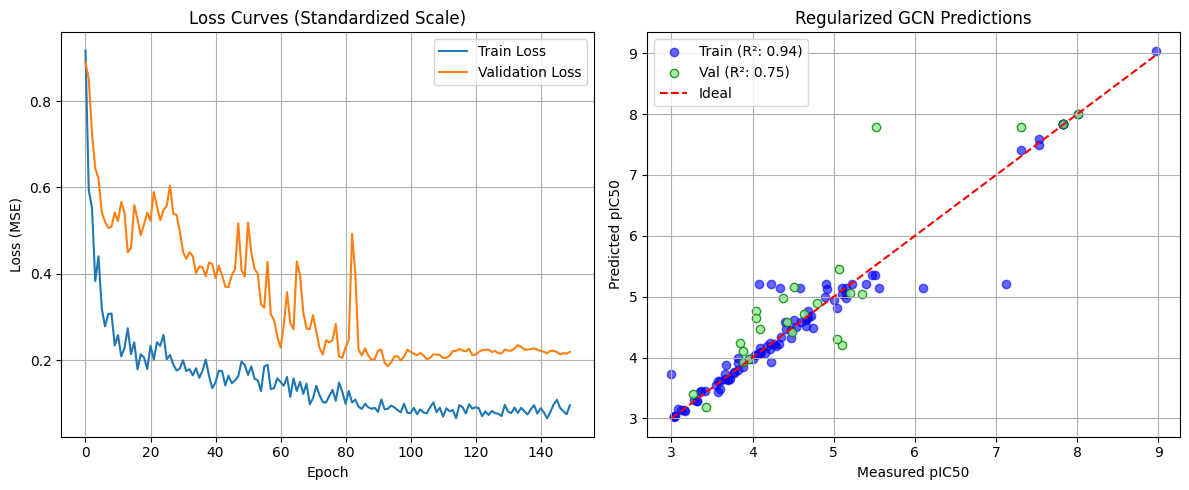

In [14]:
# 1. Fungsi bantu untuk mengekstrak prediksi dan target dari DataLoader
def evaluate_loader(model, loader):
    model.eval()
    preds_scaled, targets_scaled = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)
            preds_scaled.extend(out.cpu().numpy().flatten())
            targets_scaled.extend(batch.y.cpu().numpy().flatten())
    
    # Mengembalikan nilai ke skala asli (unscaled)
    preds_unscaled = std_unscale(np.array(preds_scaled))
    targets_unscaled = std_unscale(np.array(targets_scaled))
    return targets_unscaled, preds_unscaled

# 2. Ekstrak hasil prediksi untuk Train dan Validation
y_train_true, y_train_pred = evaluate_loader(model_rec, train_loader_rec)
y_val_true, y_val_pred = evaluate_loader(model_rec, val_loader_rec)

# 3. Hitung skor R² untuk masing-masing set
train_r2 = r2_score(y_train_true, y_train_pred)
val_r2 = r2_score(y_val_true, y_val_pred)

# 4. Plot Loss Curves dan Scatter Plot
plt.figure(figsize=(12, 5))

# Subplot 1: Loss Curves
plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.title('Loss Curves (Standardized Scale)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

# Subplot 2: Actual vs Predicted pIC50 (Train vs Validation)
plt.subplot(1, 2, 2)
plt.scatter(
    y_train_true,
    y_train_pred,
    label=f'Train (R²: {train_r2:.2f})',
    c='blue',
    alpha=0.6
)
plt.scatter(
    y_val_true,
    y_val_pred,
    label=f'Val (R²: {val_r2:.2f})',
    c='lightgreen',
    alpha=0.8,
    edgecolors='g'
)

# Garis Regresi Ideal (y = x)
min_val = min(min(y_train_true), min(y_val_true))
max_val = max(max(y_train_true), max(y_val_true))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal')

plt.title('Regularized GCN Predictions')
plt.xlabel('Measured pIC50')
plt.ylabel('Predicted pIC50')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
import pandas as pd
import torch
from torch_geometric.loader import DataLoader

# ==============================================================================
# LANGKAH 1: Ambil Dataset dari GitHub & Filter Hanya Kolom SMILES
# ==============================================================================
url_dataset = "https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/hasil%20skrining.csv"
df_raw = pd.read_csv(url_dataset)

# Cari nama kolom SMILES (apakah 'Smiles' atau 'SMILES')
smiles_col = 'Smiles' if 'Smiles' in df_raw.columns else 'SMILES'

# Buat dataframe baru yang HANYA berisi kolom Smiles
df_prediksi = df_raw[[smiles_col]].copy()
df_prediksi.columns = ['Smiles']  # Samakan nama kolom menjadi 'Smiles'

print("Langkah 1 Selesai: Berhasil menyaring kolom Smiles.")
display(df_prediksi.head())

Langkah 1 Selesai: Berhasil menyaring kolom Smiles.


,Smiles
0,C/N=C(\N)c1ccc(/C=C2/CCCC/C(=C/c3ccc(C(=N)N)cc...
1,O=C1/C(=C/c2ccc(N3CCOCC3)cc2)CC/C1=C\c1ccc(N2C...
2,N=C(N)c1ccc(/C=C2/CC(c3ccccc3)C/C(=C\c3ccc(C(=...
3,O=C(/C=C/c1ccc([N+](=O)[O-])cc1)/C=C/c1ccc([N+...
4,COc1ccc(/C=C/C(=O)/C=C/c2ccc(OC)c(OC)c2)cc1OC
